<a href="https://colab.research.google.com/github/carn51/Assignment-1/blob/main/ideas_151026_1133.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First analysis

In [181]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [182]:
df = pd.DataFrame(pd.read_csv('/content/Schizophrenia _Dataset(5).csv'))
df.head()

,Diagnosis,Anhedonia,Apathy,Appetite,Concentration,Content,Delay,Delusion,Dep_Mood,Focus,...,Race,Rumination,Sex,Sleep,Stress,Suspicious,Tension,Tired,Unusual_Thought,Withdrawal
0,1,4.501446,3.056575,9.283891,8.305502,0.006142,Yes,1.170842,8.177884,8.305502,...,White,5.041432,Female,6.552082,5.915492,3.991749,6.371877,4.537270,3.744410,5.242819
1,0,5.432608,0.307721,25.809400,5.060206,0.062209,Yes,2.272548,11.162913,5.060206,...,White,4.656790,Male,5.558434,4.008265,NaN,2.238665,6.113746,0.720458,3.797242
2,0,6.557500,-1.412208,24.842012,6.504229,0.071532,No,1.439095,5.887363,6.504229,...,Black,7.290494,Female,5.787561,7.177926,NaN,6.992499,5.557374,-0.491255,4.421288
3,0,5.429568,1.686157,24.175853,6.994948,0.278345,No,1.380185,8.943851,6.994948,...,White,6.759339,Female,6.787287,2.866815,NaN,4.018286,6.136269,0.765388,2.299562
4,1,5.099846,-0.612506,45.808490,5.869212,0.004214,Yes,1.237976,6.741627,5.869212,...,Black,6.190019,Male,7.748312,6.798220,5.103103,5.063542,4.213723,0.705895,6.547707


Idea 0: preprocessing... pipeline

In [183]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score
import torch
import torch.nn as nn
import torch.optim as optim

#FOR NOW
from sklearn.impute import KNNImputer

In [188]:
from sklearn.metrics._plot.confusion_matrix import confusion_matrix
def neural_network_func(df, input_cols):
  def preprocessing_pipeline(df):
    X = df.drop(columns = ['Diagnosis', 'Tired'])
    y = df['Diagnosis']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=23)

    num_cols = X.select_dtypes(include = ['number']).columns
    cat_cols = X.select_dtypes(exclude = ['number']).columns

    num_pipe = Pipeline(steps = [
        ('num_imputer', KNNImputer()),
        ('scaler', StandardScaler())
    ])

    cat_pipe = Pipeline(steps = [
        ('encoder', OneHotEncoder(sparse_output=False))
    ])

    prep = ColumnTransformer(transformers = [
        ('num_prep', num_pipe,  num_cols),
        ('cat_prep', cat_pipe, cat_cols)
    ]).set_output(transform='pandas')

    pipe = Pipeline(steps = [
       ('preprocessor', prep)
    ])

    return prep.fit_transform(X_train), prep.transform(X_test), y_train, y_test

  X_trained = preprocessing_pipeline(df)[0]
  X_tested = preprocessing_pipeline(df)[1]
  y_trained = preprocessing_pipeline(df)[2]
  y_tested = preprocessing_pipeline(df)[3]

  X_train_tensor = torch.tensor(np.array(X_trained), dtype = torch.float32)
  X_test_tensor = torch.tensor(np.array(X_tested), dtype = torch.float32)
  y_train_tensor = torch.tensor(np.array(y_trained), dtype = torch.long)
  y_test_tensor = torch.tensor(np.array(y_tested), dtype = torch.long)

  class NeuralNetwork0(nn.Module):
    def __init__(self):
      super().__init__()
      self.fc1 = nn.Linear(input_cols, 100)
      self.relu1 = nn.ReLU()
      self.fc2 = nn.Linear(100, 2)
      self.output = nn.Sigmoid()

    def forward(self, x):
      x = self.fc1(x)
      x = self.relu1(x)
      x = self.fc2(x)
      x = self.output(x)
      return x

  model = NeuralNetwork0()

  loss_func = nn.CrossEntropyLoss()
  opt = optim.Adam(model.parameters(), lr=0.01)
  num_epochs = 100

  losses_list = []

  for epoch in range(num_epochs):
    opt.zero_grad()
    outputs = model(X_test_tensor)
    loss = loss_func(outputs, y_test_tensor)
    loss.backward()
    opt.step()
    losses_list.append(loss.item())

  return (losses_list), outputs, y_test_tensor

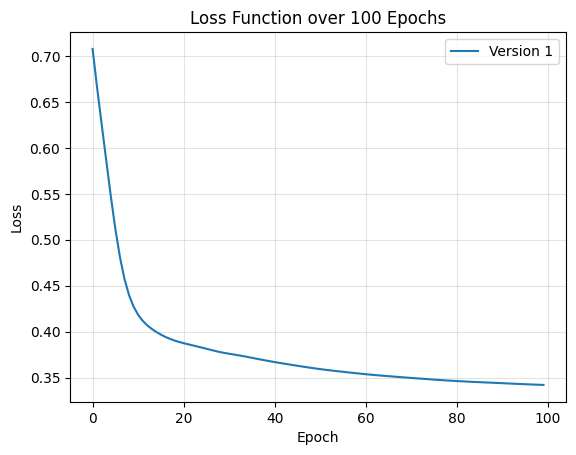

In [189]:
loss_to_plot = neural_network_func(df, input_cols = 31)[0]

plt.title('Loss Function over 100 Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(alpha = 0.35)
plt.plot(pd.Series(loss_to_plot), label = 'Version 1')
plt.legend()

Threshold to turn into 0 and 1... my function used within main func/ have as parameter in outer function. Decide by examining distrbutions of each prob and later experimentation/ try and acquire domain knowledge... relate to 0.05 somehow considering statistical definition.

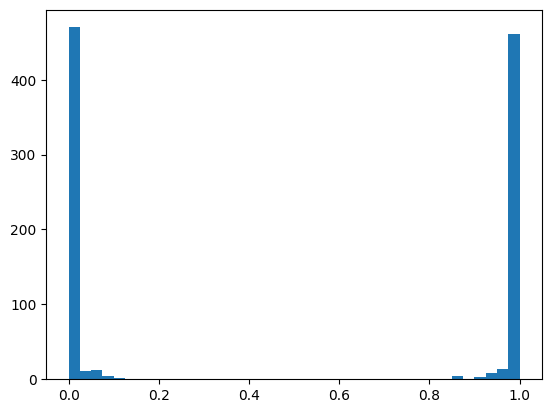

In [191]:
outputs_array = neural_network_func(df, input_cols = 31)[1][:, 1].detach().numpy()
outputs_series = pd.Series(outputs_array)
plt.hist(outputs_series, bins = 40)   #p of 1... a diagnosis of schizophrenia
plt.show()    #fairly sure of outcome... 0.8 thresh

Adapt outputs with 0.8 as threshold

In [203]:
def output_manipulation(df, outputs, input_cols):
  #convert to series
  outputs_array = neural_network_func(df, input_cols = input_cols)[1][:, 1].detach().numpy()
  outputs_series = pd.Series(outputs_array)
  classified_list = []
  for val in outputs_series:
    if val > 0.8:
      classified_list.append(1)
    else:
      classified_list.append(0)
  return classified_list

output_manipulation(df, neural_network_func(df, input_cols = 31)[1], input_cols=31)

[1,
 1,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 1,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 1,
 0,
 1,
 1,
 1,
 0,
 0,
 1,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 0,
 0,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 1,
 1,
 1,
 1,
 1,
 1,
 1,
 0,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 1,
 0,
 1,
 0,
 1,
 1,
 0,
 0,
 1,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 1,
 1,
 1,
 0,
 1,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 1,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 1,
 0,
 1,
 1,
 1,
 0,
 0,


Evaluation metrics outputted

In [195]:
from sklearn.metrics import accuracy_score

In [206]:
def combined_function_nn(df, input_cols):
  #manipulate y_test and preds to get 'metrics'
  res0 = neural_network_func(df, input_cols)
  output_preds = output_manipulation(df, res0[1], input_cols=input_cols)
  #metrics
  y_test = neural_network_func(df, input_cols=input_cols)[2]
  acc_score = accuracy_score(y_test, output_preds)
  #print(list(zip(y_test, output_preds)))
  print(acc_score)

combined_function_nn(df, input_cols = 31)

0.974


Dropping highest importance (according to RF). Justofy in report wrt multcollinearity

In [207]:
from sklearn.ensemble import RandomForestClassifier

In [208]:
def importances(df):
  def rf_pipeline(df):
    X = df.drop(columns = ['Diagnosis', 'Tired'])
    y = df['Diagnosis']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=23)

    num_cols = X.select_dtypes(include = ['number']).columns
    cat_cols = X.select_dtypes(exclude = ['number']).columns

    num_pipe = Pipeline(steps = [
        ('num_imputer', KNNImputer()),
        ('scaler', StandardScaler())
    ])

    cat_pipe = Pipeline(steps = [
        ('encoder', OneHotEncoder(sparse_output=False))
    ])

    prep = ColumnTransformer(transformers = [
        ('num_prep', num_pipe,  num_cols),
        ('cat_prep', cat_pipe, cat_cols)
    ]).set_output(transform='pandas')

    pipe = Pipeline(steps = [
       ('preprocessor', prep),
       ('rf_feat_importance', RandomForestClassifier())
    ])

    pipe.fit(X_train,  y_train)
    pipe.predict(X_test)
    feat_importances = pd.Series(pipe[-1].feature_importances_)

    plt.title('Feature Importances')
    plt.xlabel('Features')
    plt.ylabel('Importance (Random Forest)')
    plt.grid(alpha = 0.3)
    plt.xticks(rotation = 90)

    pd.Series(sorted(feat_importances)).plot(kind = 'bar')
    plt.show()

    print(list(sorted(list(zip(pipe[-1].feature_names_in_, feat_importances)))))
    #print(pipe[-1].fit(X_train, y_train).feature_importances_)

  rf_pipeline(df)

Re-evaluation preferred to static list

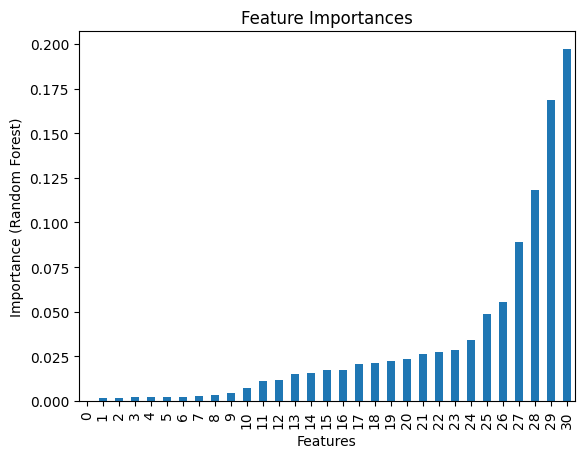

[('cat_prep__Delay_No', 0.0021815390692597188), ('cat_prep__Delay_Yes', 0.002206442659533846), ('cat_prep__Housing_Stable', 0.0015607346567863803), ('cat_prep__Housing_Unstable', 0.002022065729830873), ('cat_prep__Race_Asian', 0.0014900134265860413), ('cat_prep__Race_Black', 0.0042872198729107655), ('cat_prep__Race_Hispanic', 0.001971407227509129), ('cat_prep__Race_White', 0.003378894068369395), ('cat_prep__Sex_Female', 0.01742813438212463), ('cat_prep__Sex_Male', 0.015465270101464548), ('num_prep__Anhedonia', 0.0343992361314189), ('num_prep__Apathy', 0.028793473004373557), ('num_prep__Appetite', 0.011091810653629635), ('num_prep__Concentration', 0.022322862345262973), ('num_prep__Content', 0.023646667157747093), ('num_prep__Delusion', 0.05561766068817343), ('num_prep__Dep_Mood', 0.014956520860016554), ('num_prep__Focus', 0.027677583405257954), ('num_prep__Hallucination', 0.02615846398188629), ('num_prep__Intrusive_Thoughts', 0.11816537800903351), ('num_prep__Participant', 0.0), ('num_

In [209]:
importances(df)

drop 0

0.973
None


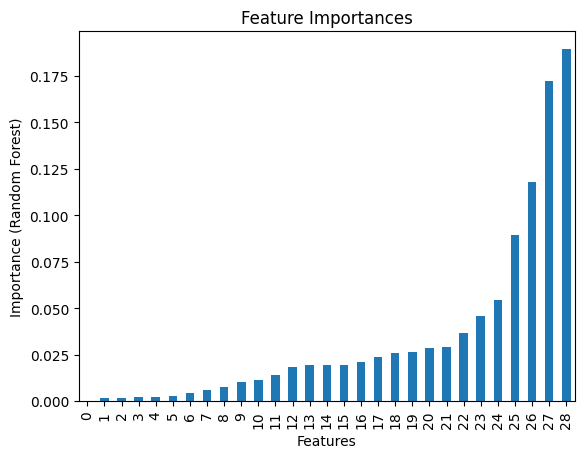

[('cat_prep__Housing_Stable', 0.001972017881411093), ('cat_prep__Housing_Unstable', 0.001723419045268609), ('cat_prep__Race_Asian', 0.0014793408941551906), ('cat_prep__Race_Black', 0.006046653514713732), ('cat_prep__Race_Hispanic', 0.0023173657576342293), ('cat_prep__Race_White', 0.004262582869395896), ('cat_prep__Sex_Female', 0.019481392226112126), ('cat_prep__Sex_Male', 0.019549204072362956), ('num_prep__Anhedonia', 0.036681491416085156), ('num_prep__Apathy', 0.02853110566403886), ('num_prep__Appetite', 0.010241360275374901), ('num_prep__Concentration', 0.023761569369360375), ('num_prep__Content', 0.02082106841152505), ('num_prep__Delusion', 0.05433002237948437), ('num_prep__Dep_Mood', 0.013893467183264174), ('num_prep__Focus', 0.028784911512611554), ('num_prep__Hallucination', 0.02633835059799934), ('num_prep__Intrusive_Thoughts', 0.11807168805012651), ('num_prep__Participant', 0.0), ('num_prep__Passive', 0.007580601055025087), ('num_prep__Pregnant', 0.00283042187774462), ('num_prep

In [211]:
df0 = df.drop(columns = ['Delay'])
print(combined_function_nn(df0, input_cols = 29))
importances(df0)

Score recording

In [ ]:
nn_scores = [0.974, 0.973]